# Surrogate generalization: 10, 13, 16 and 20 layers

Compare the exported forward surrogate **through iBeamLab batch inference** against the saved SIMNRA RBS datasets. Each system contains 10,000 physical samples, paired expected counts and Poisson observations. Every prediction uses the stored sample, exposure and calibration; no fitting is performed.

Run this notebook in a fresh kernel with the current ONNX-enabled extension. It streams bounded batches, retains scalar scores and only 28 plotted examples, and never reloads training data or modifies checkpoints. Export the trained package first, or point `MODEL_PATH` to an existing package.


In [1]:
from pathlib import Path
import sys
import json

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "CMakeLists.txt").is_file() and (p / "ibeamlab").is_dir())
HERE = ROOT / "examples/DataGeneration/test_generalization_layers"
# Prefer the existing isolated ONNX build; set an explicit CPU/CUDA build if needed.
EXTENSION_DIR = next((p for p in (
    ROOT / "build/onnx/bin", ROOT / "build/inference-tests/bin",
    ROOT / "build/local/Release/bin") if p.is_dir()), ROOT / "build/local/Release/bin")
MODEL_PATH = ROOT / "examples/ibeamnet/packages/forward.ibm"
LAYERS = (10, 13, 16, 20)
PROVIDER = "cpu"  # "cuda" requires a CUDA-enabled native build.
DEVICE_ID = 0

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(EXTENSION_DIR))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import ibeamlab as ibl
from examples.DataGeneration.test_generalization_layers.comparison import (
    case_information, load_surrogate, evaluate, select_examples,
)
print("Package:", MODEL_PATH)
from ibeamlab._engine import engine
print("Native extension:", engine().__file__)
print("Available providers:", ibl.available_execution_providers())
if PROVIDER not in ibl.available_execution_providers():
    raise RuntimeError("Select an ONNX-enabled EXTENSION_DIR for this provider and restart the kernel.")


Package: D:\ibeamlab\examples\ibeamnet\packages\forward.ibm
Native extension: D:\ibeamlab\build\inference-tests\bin\_ibeamlab.cp311-win_amd64.pyd
Available providers: ['cpu']


C:\Users\local_admin\.conda\envs\DL\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the package and evaluation grids

The measured spectrum length varies with sample and calibration. An **in-memory evaluation copy** sets the native rebin length to cover the largest measured full-pileup spectrum and permits zero counts outside reference coverage. Weights, numerical transforms and the packaged pileup resolving time are preserved. Native inference applies rebinning, exposure scaling and pileup for each requested setup; scoring and plots use only that sample's recorded channels. No measured counts are interpolated, rescaled or padded for scoring.

This explicitly changes the grid/coverage policy for evaluation; it does not alter the `.ibm` file. A package must declare bare RBS reference spectra with `Rebin -> ExposureScale -> Pileup`. Missing operations are reported rather than silently inserted. Beam energy, resolution and other fixed settings must agree with the model contract.


In [2]:
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"No exported surrogate at {MODEL_PATH}. Set MODEL_PATH or run the export cell "
        "in examples/ibeamnet/train/train.ipynb first (RUN_EXPORT=True)."
    )
CASES = case_information(HERE, LAYERS)
options = ibl.InferenceOptions(execution_provider=PROVIDER, device_id=DEVICE_ID,
                               intra_op_threads=1, inter_op_threads=1, allow_tf32=False)
model, evaluation_contract = load_surrogate(MODEL_PATH, CASES, options)
display(pd.DataFrame([{ "layers": layers, "samples": item["samples"],
                       "maximum_channels": item["maximum_channels"] }
                     for layers, item in CASES.items()]))
print(json.dumps(evaluation_contract, indent=2))


,layers,samples,maximum_channels
0,10,10000,6317
1,13,10000,6315
2,16,10000,6313
3,20,10000,6315


{
  "package": "D:\\ibeamlab\\examples\\ibeamnet\\packages\\forward.ibm",
  "package_sha256": "dbe8bf1e3c9f823694acac728ddde6983307d3b90a505f66c4e3be1fef42e0d4",
  "bare_channels": 3159,
  "processed_channels": 6317,
  "rebin_coverage": "zero_outside_reference",
  "comparison_support": "recorded SIMNRA channels only",
  "pileup_tau_seconds": 4e-07
}


## Evaluate chi-square in true batches

On the fixed per-sample region $M=\{i:\mu_i\geq\text{MINIMUM_EXPECTED}\}$, where $\mu$ is noiseless SIMNRA and $p$ is the surrogate prediction:

- **Chi-square:** $\chi^2=\sum_{i\in M}(y_i-p_i)^2/(1+y_i)$.
- **Chi-square per bin:** $\chi^2/|M|$. No fitted-parameter correction is made.
- **Noise baseline:** $\sum_{i\in M}(y_i-\mu_i)^2/(1+y_i)\,/|M|$. This uses the same observed-data denominator; its low-count expectation need not equal 1.
- **Model discrepancy:** $\sum_{i\in M}(p_i-\mu_i)^2/(1+\mu_i)\,/|M|$ isolates surrogate/physical-processing differences from Poisson fluctuations.

ROI selection uses expected counts, never observed fluctuations or model predictions. The additive 1 keeps zero observed counts well-defined; this is a diagnostic score, not an exact small-count chi-square significance test. All raw channel lengths and evaluated-bin counts are saved. Keep the same thresholds when comparing runs.


In [3]:
from datetime import datetime, timezone

# All evaluation-loop controls are here. None evaluates all 10,000 rows per case.
BATCH_SIZE = 128
LIMIT_PER_CASE = None  # Set e.g. 100 for a quick preview.
MINIMUM_EXPECTED = 1.0
RESULTS = HERE / "comparisons" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

bar = None
active_layers = None
def update(layers, completed, total):
    global bar, active_layers
    if layers != active_layers:
        if bar is not None:
            bar.close()
        bar = tqdm(total=total, desc=f"{layers}-layer inference", unit="spectra")
        active_layers = layers
    bar.update(completed - bar.n)

try:
    score_path = evaluate(model, CASES, RESULTS, batch_size=BATCH_SIZE,
        limit_per_case=LIMIT_PER_CASE, minimum_expected=MINIMUM_EXPECTED,
        progress=update, provenance=evaluation_contract)
finally:
    if bar is not None:
        bar.close()
print("Saved:", RESULTS)



10-layer inference:   0%|          | 0/10000 [00:00<?, ?spectra/s]


10-layer inference:   3%|▎         | 256/10000 [00:00<00:11, 874.98spectra/s]


10-layer inference:   4%|▍         | 384/10000 [00:00<00:15, 608.09spectra/s]


10-layer inference:   5%|▌         | 512/10000 [00:00<00:17, 531.82spectra/s]


10-layer inference:   6%|▋         | 640/10000 [00:01<00:18, 500.52spectra/s]

...


20-layer inference:  97%|█████████▋| 9728/10000 [00:29<00:00, 341.09spectra/s]


20-layer inference:  99%|█████████▊| 9856/10000 [00:29<00:00, 341.80spectra/s]


20-layer inference: 100%|█████████▉| 9984/10000 [00:29<00:00, 341.08spectra/s]


20-layer inference: 100%|██████████| 10000/10000 [00:29<00:00, 333.35spectra/s]

Saved: D:\ibeamlab\examples\DataGeneration\test_generalization_layers\comparisons\20261030T132720_945904Z


## Compare distributions across layer counts

The noise baseline uses the same observed-data denominator as the model score. Its expectation approaches 1 at high counts but need not equal 1 at low counts. Report medians and upper quantiles as well as averages so that poor predictions remain visible.


,samples,mean_chi2_per_bin,median_chi2_per_bin,p90_chi2_per_bin,p99_chi2_per_bin,mean_noise_baseline,mean_model_discrepancy
layers,,,,,,,
10,10000,6.558628,4.376497,12.579321,40.157071,1.011165,5.428101
13,10000,6.978828,4.691015,13.092880,41.003344,1.011656,5.820434
16,10000,13.431320,6.145084,23.242272,87.618746,1.011269,11.480796
20,10000,78.597302,16.975772,124.961907,1127.384868,1.011481,68.737959


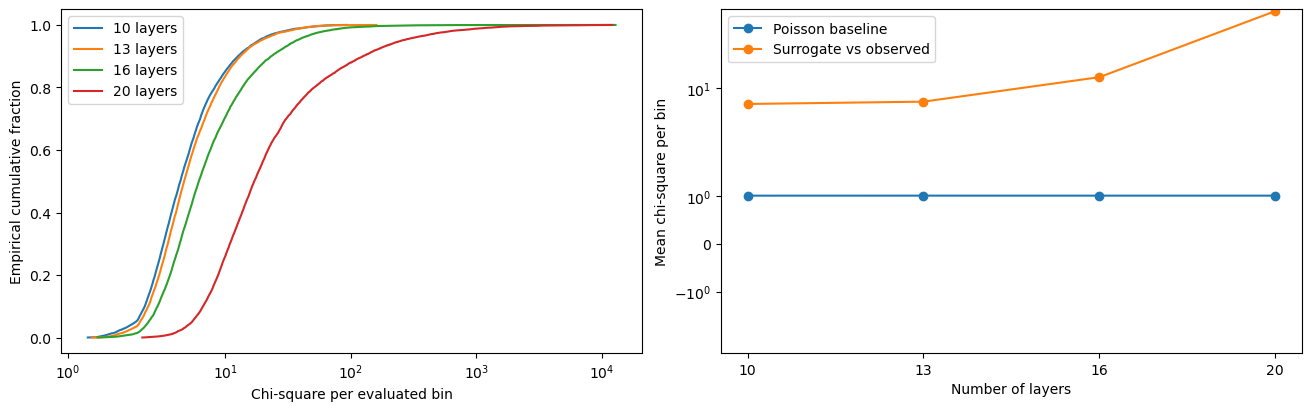

In [4]:
scores = pd.read_csv(score_path)
summary = scores.groupby("layers").agg(
    samples=("sample_index", "size"), mean_chi2_per_bin=("chi2_per_bin", "mean"),
    median_chi2_per_bin=("chi2_per_bin", "median"),
    p90_chi2_per_bin=("chi2_per_bin", lambda s: s.quantile(.9)),
    p99_chi2_per_bin=("chi2_per_bin", lambda s: s.quantile(.99)),
    mean_noise_baseline=("noise_chi2_per_bin", "mean"),
    mean_model_discrepancy=("model_error_per_bin", "mean"),
)
display(summary)
summary.to_csv(RESULTS / "summary.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for layers, group in scores.groupby("layers"):
    values = np.sort(group.chi2_per_bin.to_numpy())
    axes[0].plot(values, np.arange(1, len(values) + 1) / len(values), label=f"{layers} layers")
axes[0].set(xscale="symlog", xlabel="Chi-square per evaluated bin", ylabel="Empirical cumulative fraction")
axes[0].legend()
positions = np.arange(len(LAYERS))
axes[1].plot(positions, summary.loc[list(LAYERS), "mean_noise_baseline"], "o-", label="Poisson baseline")
axes[1].plot(positions, summary.loc[list(LAYERS), "mean_chi2_per_bin"], "o-", label="Surrogate vs observed")
axes[1].set(xticks=positions, xticklabels=LAYERS, xlabel="Number of layers", ylabel="Mean chi-square per bin", yscale="symlog")
axes[1].legend()
fig.savefig(RESULTS / "chi_square_distributions.png", dpi=180)
plt.show()


## Spectrum overlays: 4 columns ? 7 rows

Each column is one layer count. Rows select the 0%, 10%, 25%, 50%, 75%, 90% and 100% quantiles of chi-square per bin, including the worst prediction. Selection is deterministic from the evaluated scores. Only these 28 samples are predicted again for plotting; the full spectral dataset is not retained in memory.

Black: Poisson observations. Blue: noiseless SIMNRA including pileup. Red: surrogate including the same requested setup and packaged pileup processing. Panels use each sample's calibrated energy axis.


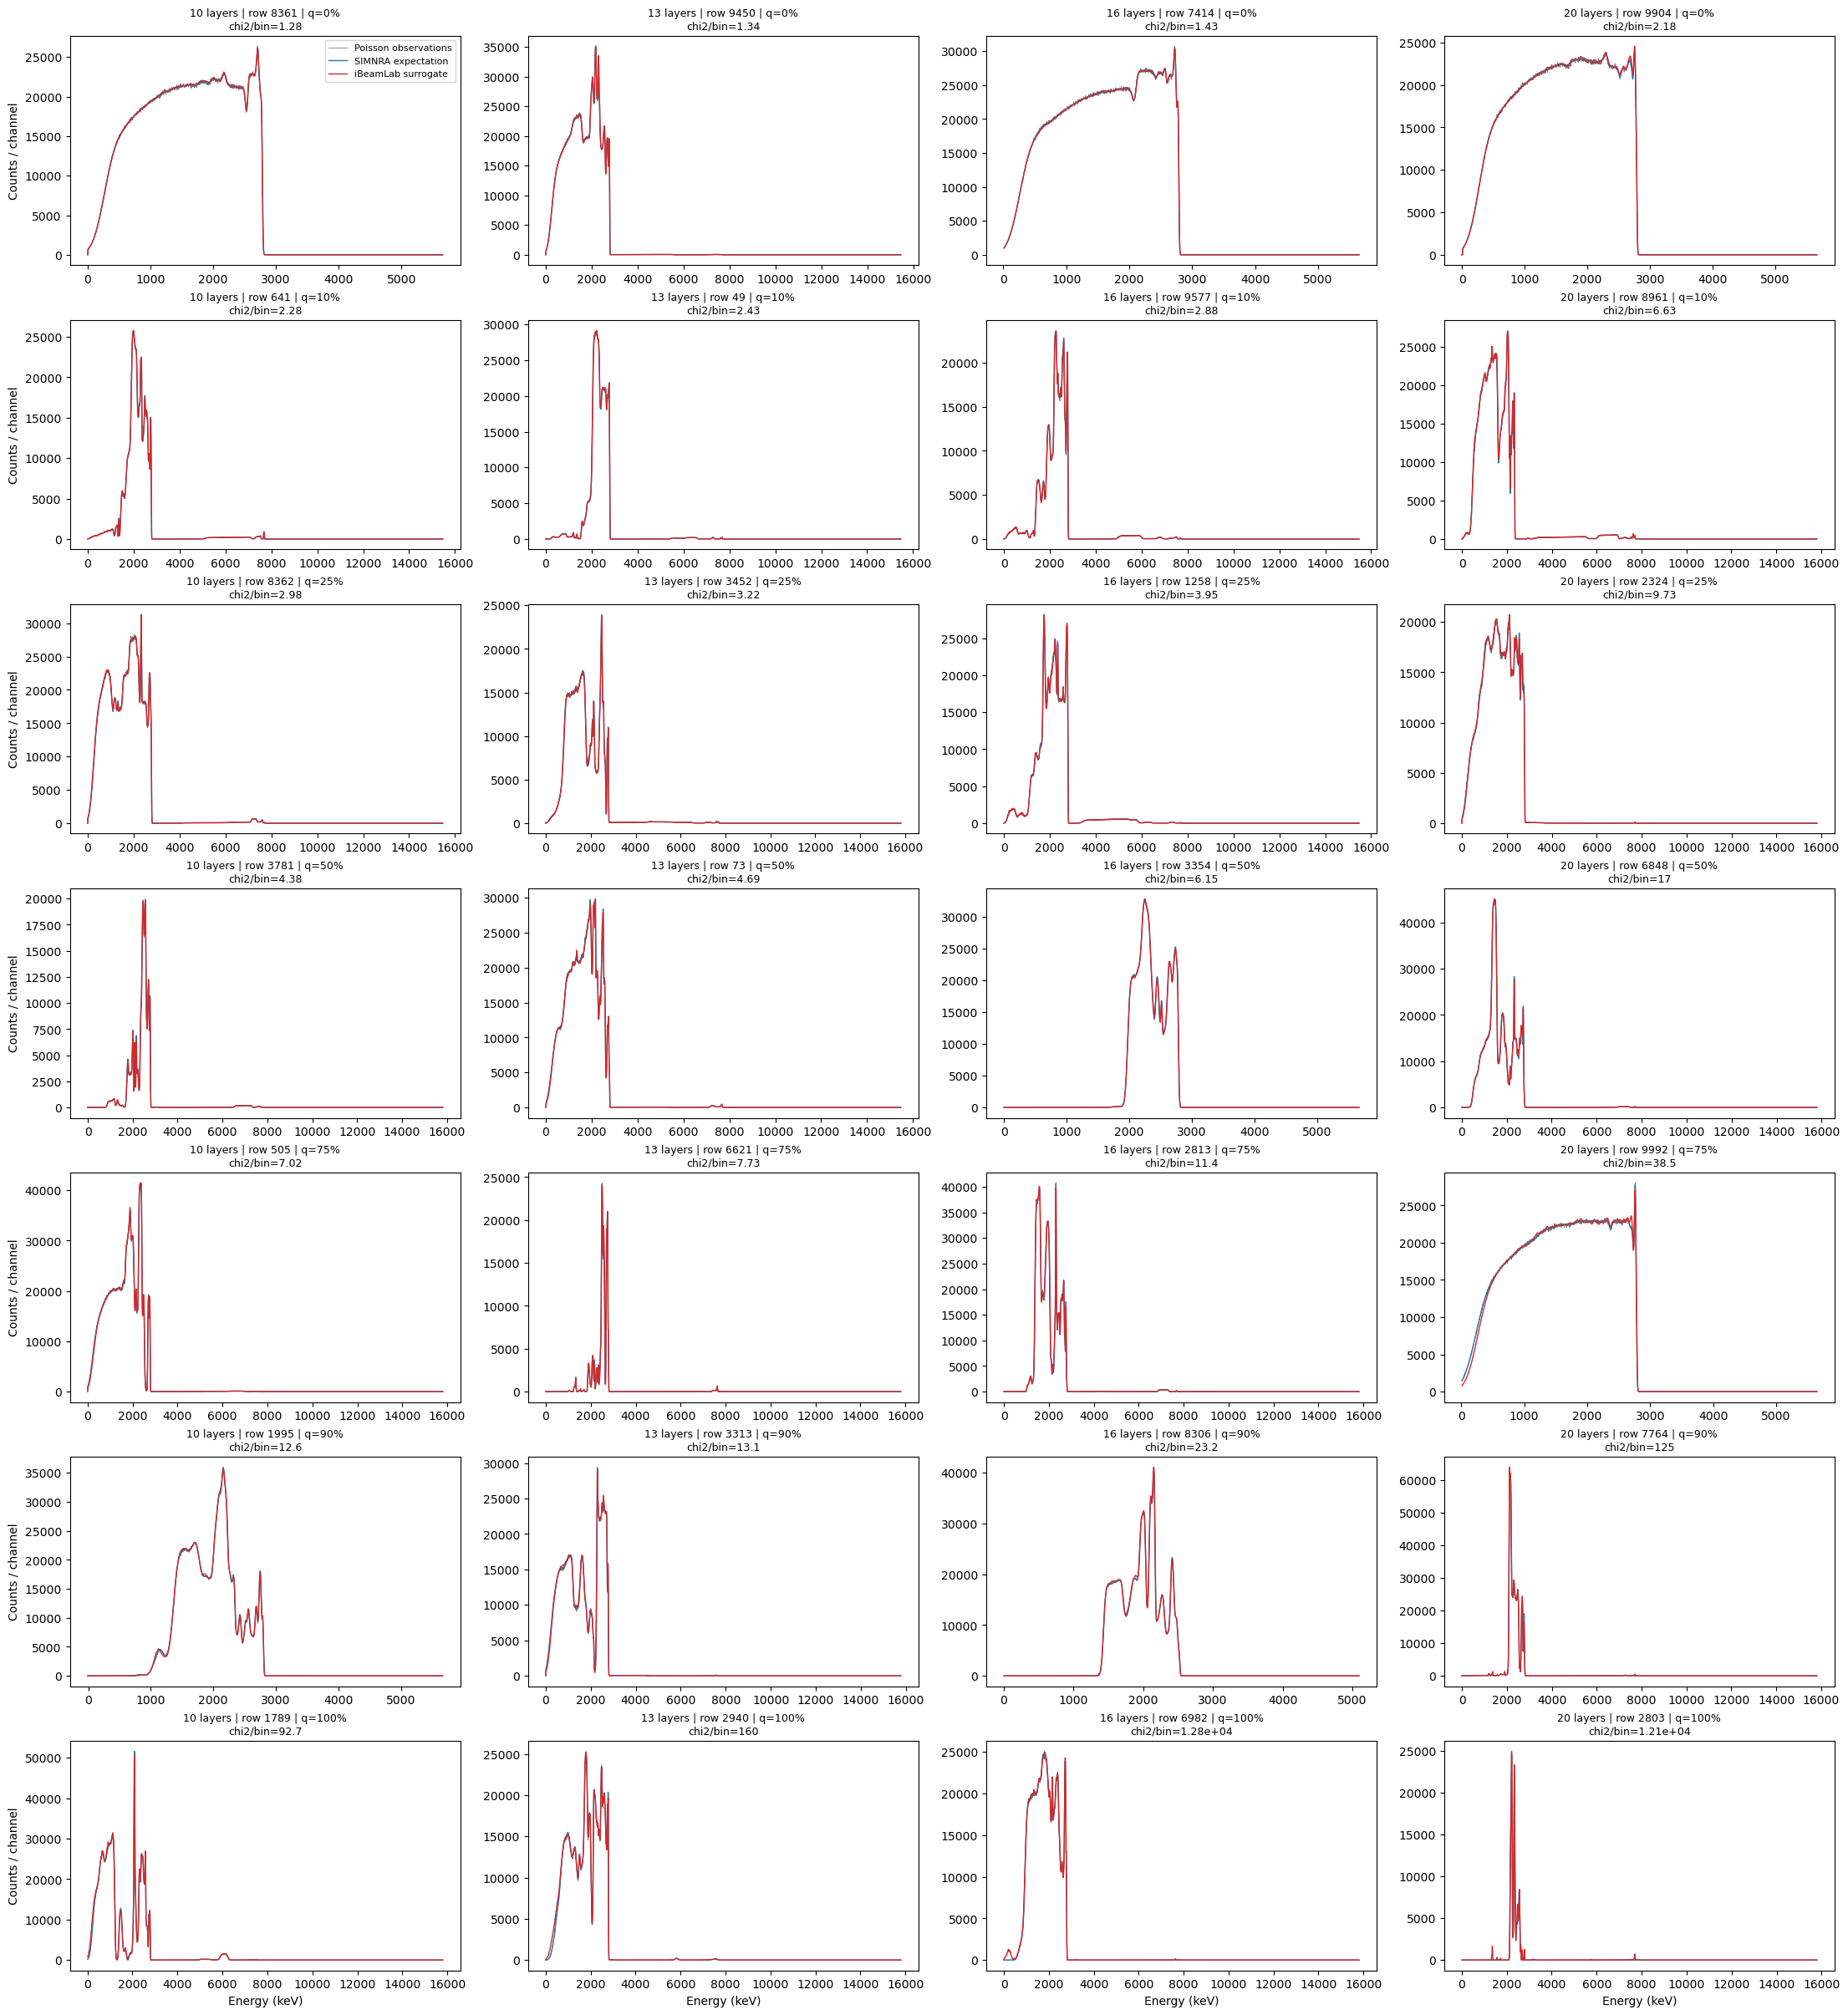

In [5]:
examples = select_examples(model, CASES, scores)
LOG_COUNTS = False  # symlog when True; zeros remain visible.
fig, axes = plt.subplots(7, 4, figsize=(22, 24), constrained_layout=True)
for col, layers in enumerate(LAYERS):
    for row, (quantile, score, arrays) in enumerate(examples[layers]):
        expected, observed, predicted, measurement = arrays
        detector = measurement.detector
        channels = np.arange(len(observed))
        energy = detector.calibrationOffset + detector.calibrationLinear * channels + detector.calibrationQuadratic * channels**2
        ax = axes[row, col]
        ax.plot(energy, observed, color="black", linewidth=.55, alpha=.55, label="Poisson observations")
        ax.plot(energy, expected, color="tab:blue", linewidth=1.0, label="SIMNRA expectation")
        ax.plot(energy, predicted, color="tab:red", linewidth=1.0, label="iBeamLab surrogate")
        ax.set_title(f"{layers} layers | row {int(score.sample_index)} | q={quantile:.0%}\nchi2/bin={score.chi2_per_bin:.3g}", fontsize=9)
        if LOG_COUNTS:
            ax.set_yscale("symlog", linthresh=1)
        if row == 6:
            ax.set_xlabel("Energy (keV)")
        if col == 0:
            ax.set_ylabel("Counts / channel")
axes[0, 0].legend(fontsize=8)
fig.savefig(RESULTS / "spectra_28_panels.png", dpi=180)
plt.show()


## Standardized residuals for the same 28 spectra

Residuals use $(y-p)/\sqrt{1+y}$ on the same scoring ROI. The horizontal ?3 lines are visual guides; small-count residuals need not be Gaussian.


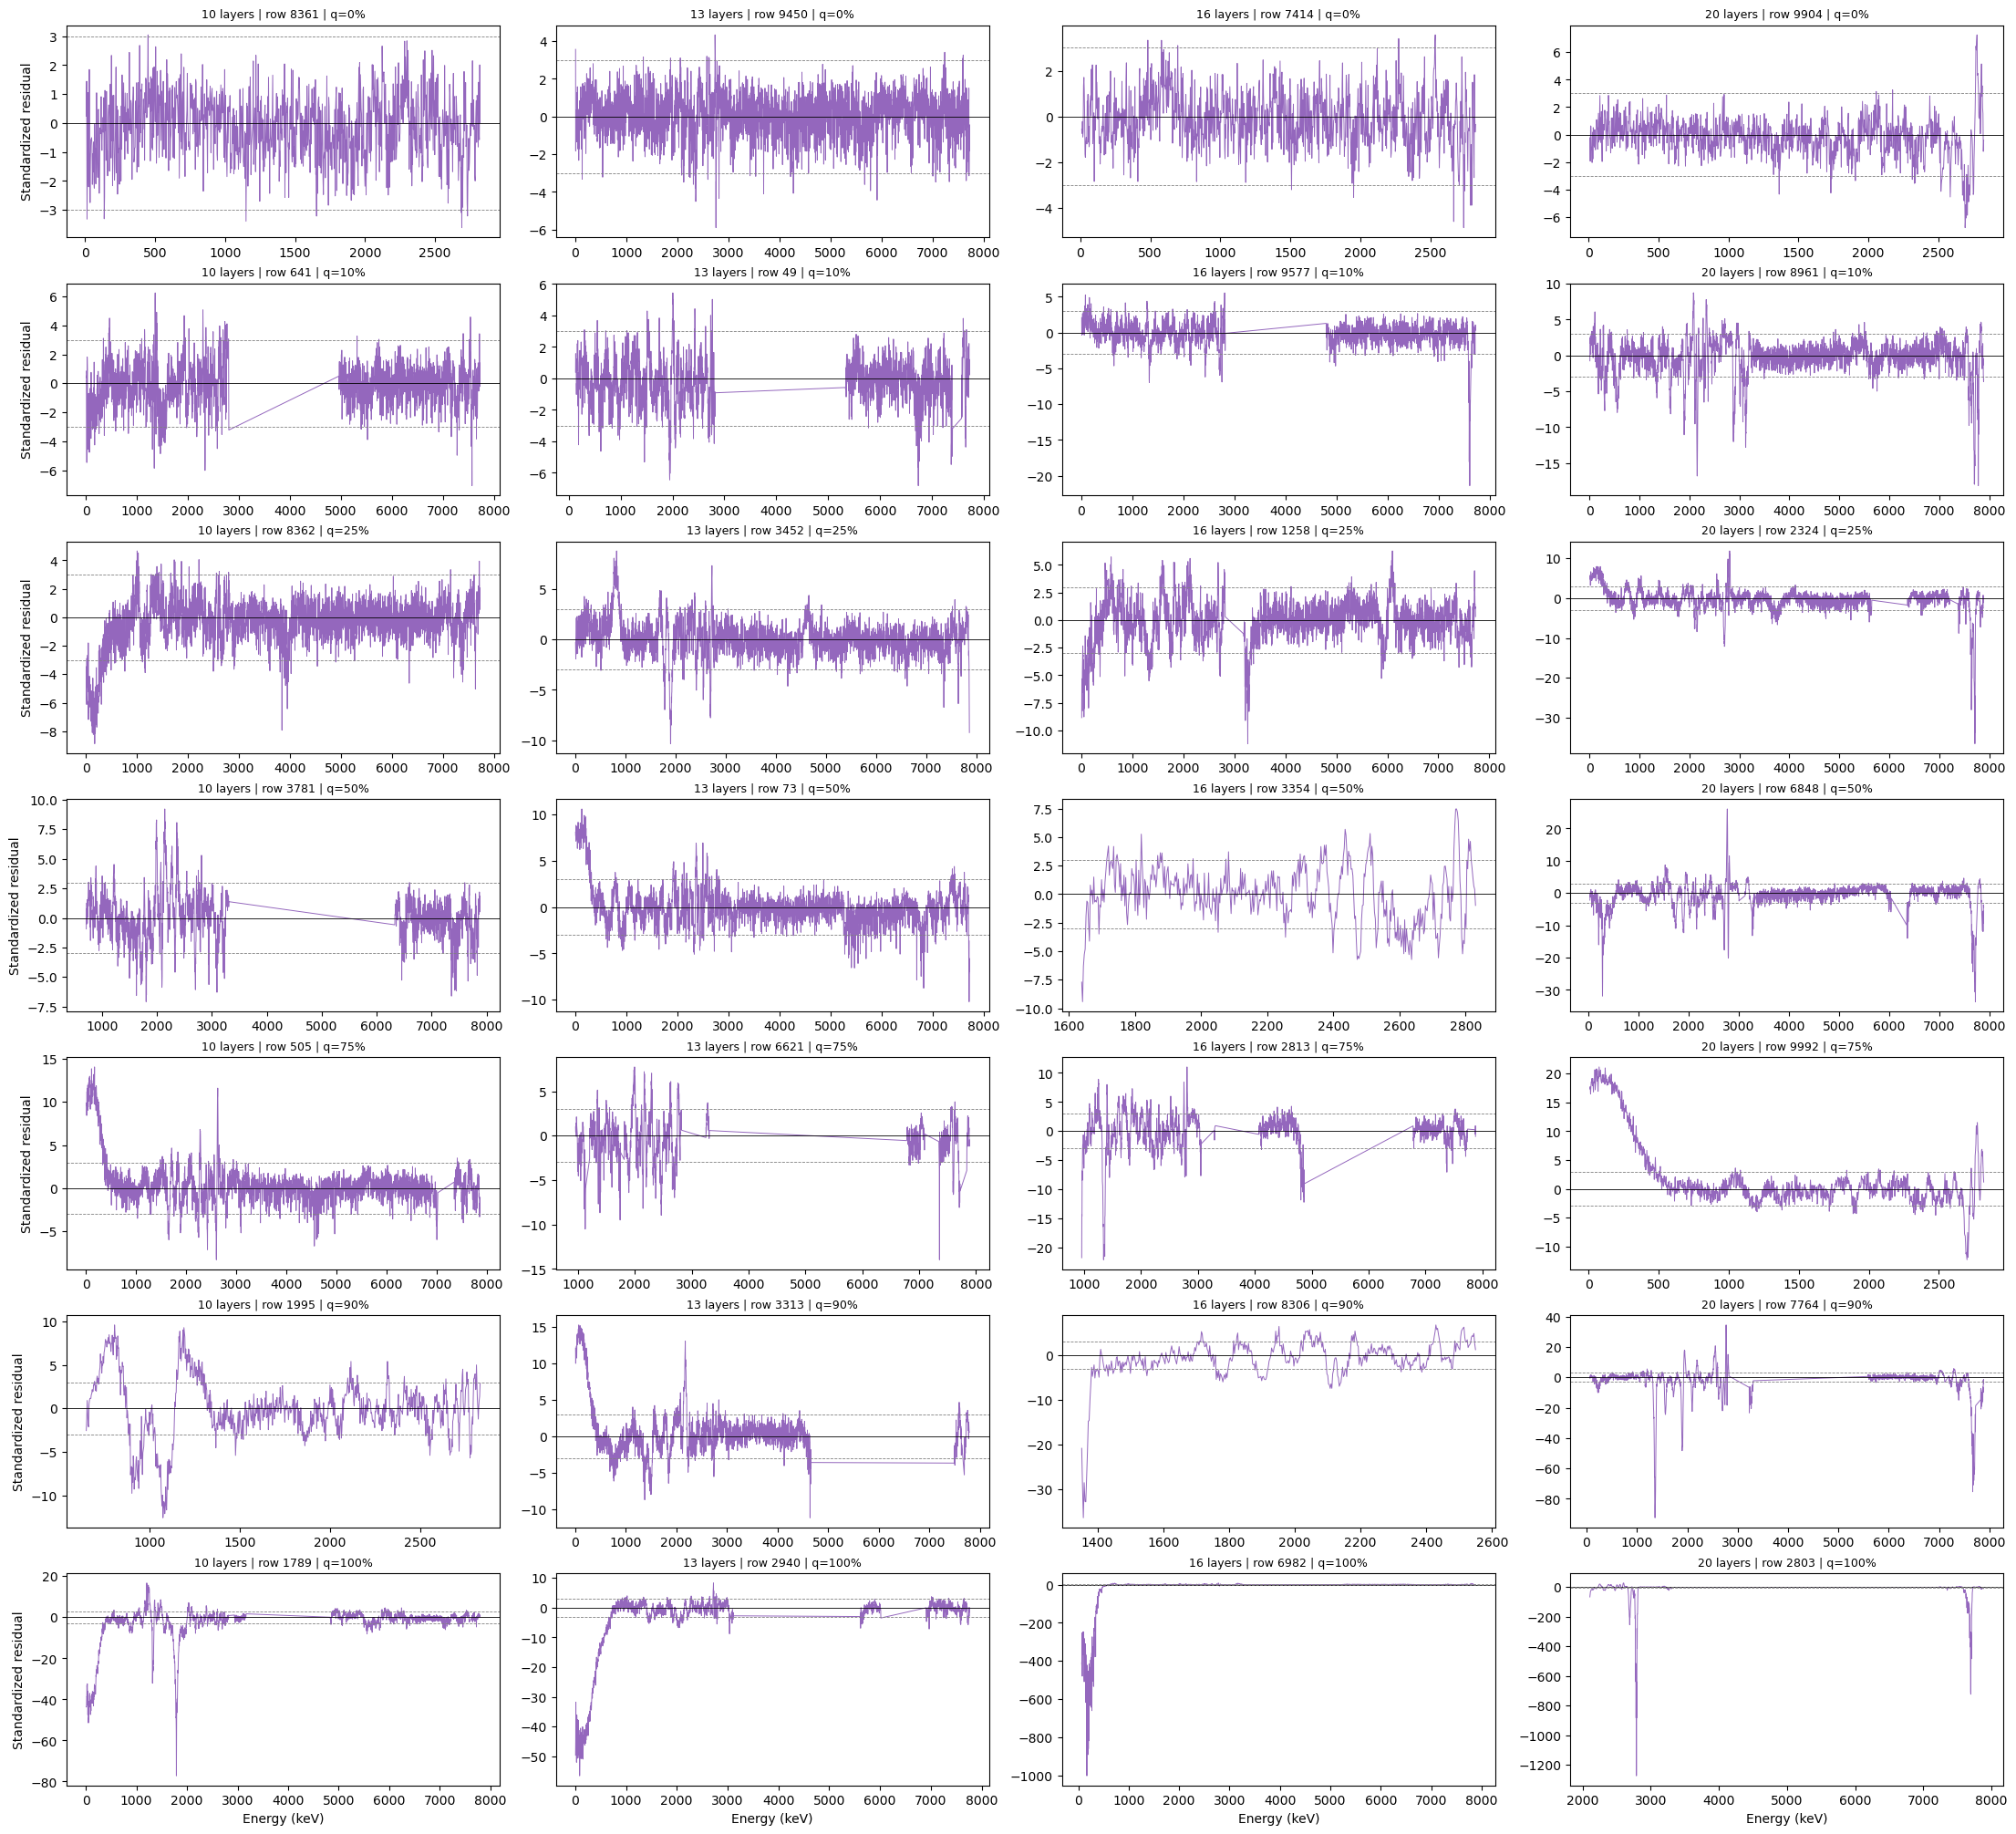

In [6]:
fig, axes = plt.subplots(7, 4, figsize=(22, 20), constrained_layout=True)
for col, layers in enumerate(LAYERS):
    for row, (quantile, score, arrays) in enumerate(examples[layers]):
        expected, observed, predicted, measurement = arrays
        channels = np.arange(len(observed))
        detector = measurement.detector
        energy = detector.calibrationOffset + detector.calibrationLinear * channels + detector.calibrationQuadratic * channels**2
        mask = expected >= MINIMUM_EXPECTED
        residual = (observed - predicted) / np.sqrt(1.0 + observed)
        ax = axes[row, col]
        ax.plot(energy[mask], residual[mask], color="tab:purple", linewidth=.7)
        ax.axhline(0, color="black", linewidth=.6)
        for level in (-3, 3):
            ax.axhline(level, color="gray", linestyle="--", linewidth=.6)
        ax.set_title(f"{layers} layers | row {int(score.sample_index)} | q={quantile:.0%}", fontsize=9)
        if row == 6:
            ax.set_xlabel("Energy (keV)")
        if col == 0:
            ax.set_ylabel("Standardized residual")
fig.savefig(RESULTS / "residuals_28_panels.png", dpi=180)
plt.show()
